#Day 3 - Global Mining Production EDA (Coal & Metals)

Setelah belajar mengenal & membersihkan data, kini Saya akan melangkah ke **eksplorasi data (EDA)** pada skala global: berapa banyak bijih yang ditambang dunia tiap tahun, komoditas apa yang mendominasi, dan berapa banyak fasilitas tambang yang beroperasi. Saya akan memakai basis data produksi tambang **nyata** yang mengumpulkan laporan dari ribuan fasilitas di berbagai negara.

🎯 **Tujuan Pembelajaran**
> - Memfilter data berdasarkan kategori (mis. hanya "Ore mined").
> - Melakukan **agregasi** dengan `groupby` (total produksi per tahun & per material).
> - Menemukan material & tahun dengan produksi tertinggi.
> - Membuat 3 grafik berbeda (garis tren, bar peringkat, boxplot skala log).

## About the Dataset

**Open Database on Global Coal and Metal Mining** — kompilasi data produksi dari fasilitas tambang batubara & logam di seluruh dunia, dilaporkan per tahun.

- **Sumber:** [Kaggle — simonjasansky/open-database-on-global-coal-and-metal-mining](https://www.kaggle.com/datasets/simonjasansky/open-database-on-global-coal-and-metal-mining)
- **Ukuran:** 12.292 baris × 12 kolom

| Kolom | Arti |
|-------|------|
| `year` | Tahun laporan produksi |
| `type` | Jenis angka (Ore mined / Ore processed / Concentrate / NM mineral) |
| `material` | Kode material (mis. `O.Fe`=bijih besi, `O.Cu`=tembaga, `O.Au`=emas) |
| `value_tonnes` | Nilai produksi dalam ton |
| `facility_id` | Pengenal fasilitas tambang |

*Beberapa kolom lain (mis. grade, sold) banyak kosong dan tidak kita pakai di notebook ini.*

## Import Library

- **pandas** → memuat & mengagregasi data tabel.
- **numpy** → operasi angka (mis. skala logaritmik).
- **matplotlib** & **seaborn** → membuat grafik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import the Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d simonjasansky/open-database-on-global-coal-and-metal-mining
!unzip open-database-on-global-coal-and-metal-mining.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/simonjasansky/open-database-on-global-coal-and-metal-mining
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.01M/1.01M [00:00<00:00, 163MB/s]

Archive:  open-database-on-global-coal-and-metal-mining.zip
  inflating: coverage_national_area_charts.pdf  
  inflating: coverage_table.pdf      
  inflating: data/capacity.csv       
  inflating: data/coal.csv           
  inflating: data/commodities.csv    
  inflating: data/facilities.gpkg    
  inflating: data/material_ids.csv   
  inflating: data/minerals.csv       
  inflating: data/ownership.csv      
  inflating: data/processing.csv     
  inflating: data/reserves.csv       
  inflating: data/source_ids.csv     
  inflating: data/transport.csv      
  inflating: data/waste.csv          
  inflating: database_model.pdf      
  inflating: materials_cov

## Import Dataset

In [7]:
df = pd.read_csv("/content/data/minerals.csv")


## Initial Exploration

In [10]:
df.head(2)

,id,facility_id,year,type,material,value_tonnes,overall_grade_ppm,amount_sold_tonnes,mine_processing,reporting_period,source_id,comment
0,1,COM00001.00,2013,Ore mined,O.bulk,1625532,NaN,NaN,NaN,NaN,det_1729,NaN
1,2,COM00001.00,2013,Ore processed,O.bulk,1625532,NaN,NaN,NaN,NaN,det_1729,NaN


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12292 entries, 0 to 12291
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  12292 non-null  int64  
 1   facility_id         12292 non-null  object 
 2   year                12292 non-null  int64  
 3   type                12292 non-null  object 
 4   material            12292 non-null  object 
 5   value_tonnes        12292 non-null  int64  
 6   overall_grade_ppm   408 non-null    float64
 7   amount_sold_tonnes  542 non-null    float64
 8   mine_processing     483 non-null    object 
 9   reporting_period    1960 non-null   object 
 10  source_id           12292 non-null  object 
 11  comment             655 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 1.1+ MB


**Interpretation:**
Berikut interpretasi sederhana menurut saya:

- Kolom inti sudah penuh (12.292 data terisi):
  - id, facility_id, year, type, material, value_tonnes, dan source_id tidak memiliki nilai kosong sama sekali.
  - Menurut saya, kolom-kolom ini sudah siap dipakai untuk melihat jumlah tonase (value_tonnes) berdasarkan tahun, fasilitas, jenis, atau material.

- Kolom detail banyak kosong:
  - overall_grade_ppm (408 terisi), mine_processing (483 terisi), amount_sold_tonnes (542 terisi), comment (655 terisi), dan reporting_period (1.960 terisi) hanya terisi pada sebagian kecil baris.
  - Menurut saya, hal ini wajar pada data laporan karena tidak semua catatan menyertakan kadar, jumlah terjual, metode pemrosesan, periode pelaporan, atau komentar.

- Tipe data cukup sesuai:
  - Ada 3 kolom int64, 2 kolom float64, dan 7 kolom object (teks/kategori).

Kesimpulan singkat dari saya:

  - analisis utama berbasis tonase, fasilitas, material, dan tahun bisa langsung dilakukan dengan aman, sementara kolom detail yang banyak kosongnya perlu dipakai dengan hati-hati agar data tidak banyak terbuang.

In [23]:
print("Jenis 'Type' : ")
print(df['type'].unique())
print("\nJumlah 'Type' : ")
print(df["type"].value_counts())
print("\nJenis 'Material' : ")
print(df['material'].unique())
print("\nRentang tahun:", int(df["year"].min()), "-", int(df["year"].max()))


Jenis 'Type' : 
['Ore mined' 'Ore processed' 'Concentrate' 'NM mineral']

Jumlah 'Type' : 
type
Ore mined        5324
Ore processed    5313
Concentrate      1612
NM mineral         43
Name: count, dtype: int64

Jenis 'Material' : 
['O.bulk' 'O.Fe' 'O.Cu' 'O.Au' 'Con.Cu' 'O.oxi' 'O.sul' 'O.Al' 'Oth.sif'
 'O.P' 'Con.Fe' 'O.FeTiO3' 'O.TiO2' 'O.Zr' 'O.Mn' 'O.Ni' 'Con.MnO'
 'Con.Pb' 'Con.Zn' 'M.dol' 'M.lim' 'O.Ag' 'Con.Mo' 'O.Nb' 'O.FeS'
 'Con.bulk' 'O.Sn' 'Con.MnCO3' 'Con.Cr' 'O.Cr' 'O.dig' 'O.Zn' 'O.leu'
 'Con.Ni' 'O.nep' 'O.pgm' 'M.lat' 'M.kao' 'Con.Li' 'Con.Ta' 'O.Li' 'O.K2O'
 'Oth.cuce' 'O.flu']

Rentang tahun: 2000 - 2020


Menurut **saya**, ringkasan ini memperlihatkan bahwa *dataset* tambang tersebut mencakup rentang waktu panjang (**2000–2020**), didominasi oleh tahap ekstraksi/pengolahan bijih awal, dan memiliki variasi material yang cukup beragam.

Berikut interpretasi sederhana menurut **saya**:

* **Didominasi `Ore mined` dan `Ore processed`:**
  - Dari total 12.292 baris, **Ore mined** (5.324) dan **Ore processed** (5.313) memiliki jumlah yang hampir berimbang dan mendominasi data. Menurut **saya**, ini menunjukkan fokus data banyak berada pada aktivitas penambangan dan pengolahan bijih mentah.

* **`Concentrate` di urutan ketiga, `NM mineral` paling sedikit:**
  - **Concentrate** berjumlah 1.612 baris, sedangkan **NM mineral** (kemungkinan *non-metallic mineral* atau kategori mineral khusus) hanya 43 baris.

* **Variasi `Material` cukup banyak (44 jenis):**
  - Kodenya terbagi ke beberapa pola awalan—seperti bijih (`O.Fe`, `O.Cu`, `O.Au`, `O.Ni`, `O.Zn`, dll.), konsentrat (`Con.Cu`, `Con.Fe`, `Con.Zn`, `Con.Ni`, dll.), mineral industri (`M.dol`, `M.lim`, `M.lat`, `M.kao`), serta lainnya (`Oth.sif`, `Oth.cuce`). Menurut **saya**, *grouping* berdasarkan awalan kode ini akan sangat membantu saat melakukan agregasi agar tidak terlalu banyak kategori terpisah.

* **Rentang tahun 2000–2020 (21 tahun):**
  - Urutan angkanya di output belum terurut kronologis (`2013`, `2014`, ..., `2000`, ..., `2020`), jadi menurut **saya** data ini mencakup periode 21 tahun penuh dan perlu dipastikan urutannya saat dianalisis per waktu.

**Kesimpulan singkat dari saya:** *dataset* ini kaya variasi material dan mencakup 21 tahun data (2000–2020), dengan porsi terbesar berada pada `Ore mined` dan `Ore processed`.

## Focus on Mined Ore

Saya akan saring hanya baris `type == "Ore mined"` dan buang baris tanpa nilai produksi.

In [26]:
ore_mined = df[df["type"] == "Ore mined"].copy()
ore_mined = ore_mined.dropna(subset=["value_tonnes", "year"])

ore_mined["year"] = ore_mined["year"].astype(int)

print("Baris 'Ore mined' terpakai:", ore_mined.shape[0])
ore_mined[["year", "material", "value_tonnes"]].head()

Baris 'Ore mined' terpakai: 5324


,year,material,value_tonnes
0,2013,O.bulk,1625532
2,2014,O.bulk,1452933
4,2015,O.bulk,1235053
6,2016,O.bulk,1297829
8,2017,O.bulk,1014369


**Interpretation:**

Penyaringan ini berjalan mulus—seluruh **5.324 baris** dengan `type == "Ore mined"` tetap utuh tanpa ada data yang terbuang karena `value_tonnes` dan `year` sudah lengkap sejak awal.

* **Semua baris `Ore mined` tetap ada (5.324 baris):**
  - Jumlahnya sama persis dengan sebelum `.dropna()`, artinya tidak ada baris yang hilang akibat nilai tonase atau tahun kosong.

* **Siap untuk analisis produksi bijih:**
  - Cuplikan `head()` memperlihatkan keterkaitan antara tahun (`2013`–`2017`), kode material (`O.bulk`), dan volume tonase (`value_tonnes`).

* **Indeks melompat (`0, 2, 4, 6, 8`):**
  - Ini wajar karena baris-baris di antaranya bukan `Ore mined`. Jika butuh indeks berurutan mulai dari nol, tinggal pakai `reset_index(drop=True)`.

Singkatnya, data `ore_mined` sebanyak 5.324 baris ini sudah bersih dan siap dipakai untuk melihat tren produksi bijih per tahun maupun per material.

## EDA and Visualization

### a) Trend in total annual ore production

In [30]:
annual_production = ore_mined.groupby("year")["value_tonnes"].sum()
annual_production.head(3)

,value_tonnes
year,
2000,1404004178
2001,1573936048
2002,1542603135


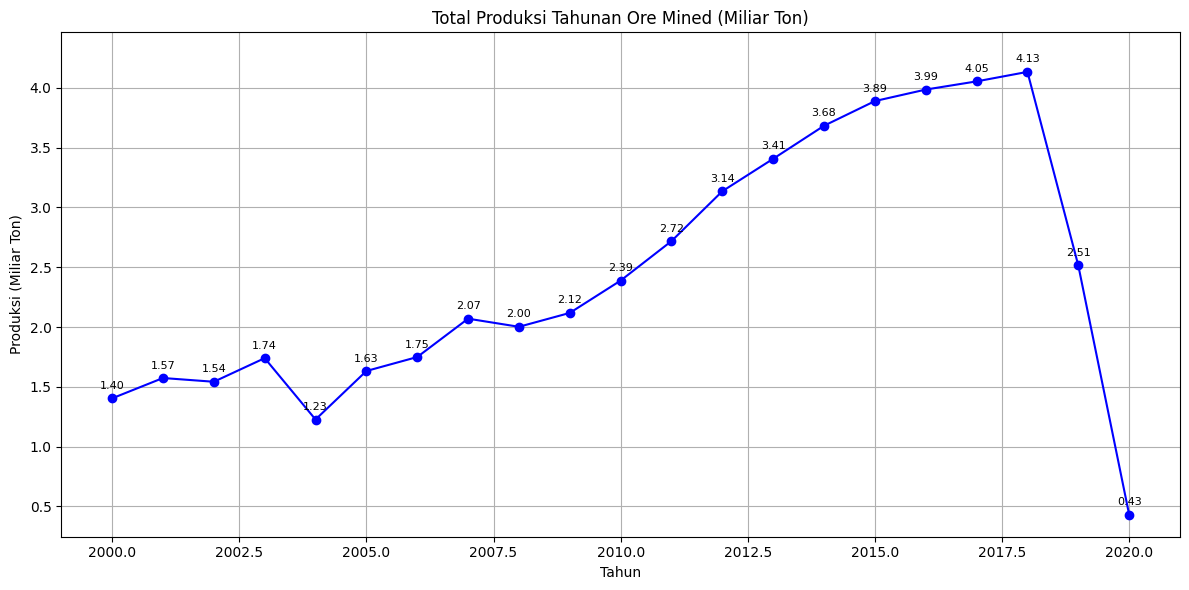

In [32]:
y_vals = annual_production.values / 1e9
x_vals = annual_production.index

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(x_vals, y_vals, "o-", color="blue")

ax.set_title("Total Produksi Tahunan Ore Mined (Miliar Ton)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Produksi (Miliar Ton)")
ax.grid(True)

# Beri sedikit ruang ekstra di atas agar label angka tidak menabrak batas atas grafik
ax.set_ylim(top=y_vals.max() * 1.08)

for x, y in zip(x_vals, y_vals):
  ax.text(
      x,
      y + (y_vals.max() * 0.015),  # geser sedikit ke atas dari titik
      f"{y:.2f}",  # ubah ke :.1f atau :.3f sesuai kebutuhan desimal
      ha="center",
      va="bottom",
      fontsize=8,
  )

plt.tight_layout()
plt.show()


**Interpretation:**


Grafik *"Total Produksi Tahunan Ore Mined (Miliar Ton)"* memperlihatkan tren kenaikan produksi bijih yang konsisten dari tahun 2000 hingga mencapai puncaknya di 2018, lalu turun tajam pada dua tahun terakhir (2019–2020).

* **Fase fluktuasi awal (2000–2008):**
  - Produksi bergerak naik-turun di kisaran **1,23 hingga 2,07 miliar ton**, dengan titik terendah di tahun 2004 (**1,23 miliar ton**) dan koreksi ringan di 2008 (**2,00 miliar ton**).


* **Fase pertumbuhan pesat (2009–2018):**
  - Sejak 2009 (**2,12 miliar ton**), produksi terus menanjak hampir setiap tahun hingga menyentuh titik tertinggi di tahun 2018 sebesar **4,13 miliar ton**.


* **Penurunan drastis di akhir periode (2019–2020):**
  - Produksi anjlok dari **4,13 miliar ton** (2018) menjadi **2,51 miliar ton** (2019), lalu turun sangat tajam ke **0,43 miliar ton** pada tahun 2020. Anjloknya angka di akhir rentang waktu ini perlu dicek apakah disebabkan oleh faktor operasional/pandemi atau kelengkapan data pelaporan pada tahun-tahun tersebut.



Singkatnya, grafik ini menyoroti pertumbuhan kuat produksi *ore mined* selama satu dekade (2009–2018) sebelum terjadi kontraksi tajam pada 2019–2020 yang layak ditelusuri penyebabnya.

### b) Which materials are mined the most? (top-10 bar chart)

In [37]:
top_10_materials = ore_mined.groupby("material")["value_tonnes"].sum().sort_values(ascending=False)
top_10_materials.head(10)

,value_tonnes
material,
O.Fe,17934392513
O.Cu,10607366879
O.bulk,8512059685
O.Au,7757300470
O.oxi,3015578946
O.Al,1711585240
O.sul,763505900
O.Ni,452971877
O.pgm,147784000


/tmp/ipykernel_626/2511447046.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x_vals, y=y_vals, palette="viridis", ax=ax)


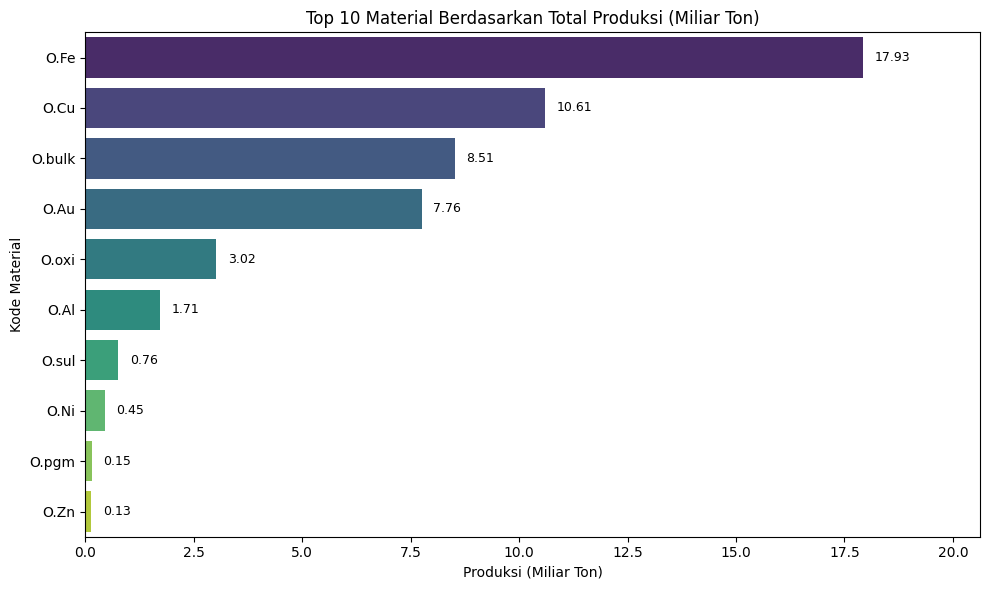

In [39]:
# Pastikan dalam satuan miliar ton jika value_tonnes masih dalam ton
x_vals = top_10_materials.values[:10] / 1e9
y_vals = top_10_materials.index[:10]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=x_vals, y=y_vals, palette="viridis", ax=ax)

ax.set_title("Top 10 Material Berdasarkan Total Produksi (Miliar Ton)")
ax.set_xlabel("Produksi (Miliar Ton)")
ax.set_ylabel("Kode Material")

# Beri ruang ekstra di kanan agar label angka tidak terpotong
ax.set_xlim(0, x_vals.max() * 1.15)

for bar in ax.patches:
  val = bar.get_width()
  ax.text(
      val + (x_vals.max() * 0.015),  # sedikit geser ke kanan dari ujung batang
      bar.get_y() + bar.get_height() / 2,  # tepat di tengah tinggi batang
      f"{val:.2f}",  # sesuaikan jumlah desimal jika perlu, misal :.3f
      va="center",
      ha="left",
      fontsize=9,
  )

plt.tight_layout()
plt.show()

**Interpretation:**

Grafik *"Top 10 Material Berdasarkan Total Produksi (Miliar Ton)"* menunjukkan bahwa volume produksi tambang didominasi oleh beberapa komoditas utama saja, dengan selisih yang cukup lebar dibanding material lainnya.

* **Bijih besi (`O.Fe`) memimpin paling jauh:**
  - Total produksinya mencapai **17,93 miliar ton**, menjadikannya material dengan volume terbesar di grafik ini.


* **Tembaga (`O.Cu`), bijih curah (`O.bulk`), dan emas (`O.Au`) di kelompok besar berikutnya:**
  - Tembaga (`O.Cu`) berada di posisi kedua dengan **10,61 miliar ton**, diikuti bijih curah/campuran (`O.bulk`) sebesar **8,51 miliar ton** dan emas (`O.Au`) sebesar **7,76 miliar ton**. Keempat material teratas ini menyumbang porsi volume yang jauh lebih besar dibanding sisanya.


* **Penurunan cukup tajam di luar empat besar:**
  - Volume turun ke **3,02 miliar ton** pada bijih oksida (`O.oxi`) dan **1,71 miliar ton** pada aluminium (`O.Al`), lalu mengecil lagi pada bijih sulfida (`O.sul` — **0,76 miliar ton**), nikel (`O.Ni` — **0,45 miliar ton**), kelompok logam platina (`O.pgm` — **0,15 miliar ton**), hingga seng (`O.Zn` — **0,13 miliar ton**).



Singkatnya, total produksi sangat terpusat pada bijih besi (`O.Fe`), tembaga (`O.Cu`), bijih curah (`O.bulk`), dan emas (`O.Au`), sementara enam material lainnya berada jauh di bawahnya.

### c) Distribution of production sizes across facilities (log-scale boxplot)

Nilai produksi antar fasilitas rentangnya sangat lebar (dari kecil sampai raksasa), jadi Saya akan pakai **skala logaritmik** agar sebaran terbaca.

In [40]:
fac_count = ore_mined.groupby("facility_id")["value_tonnes"].sum()
fac_count.head(3)

,value_tonnes
facility_id,
COM00001.00,8702065
COM00002.00,14520000
COM00004.00,2450000


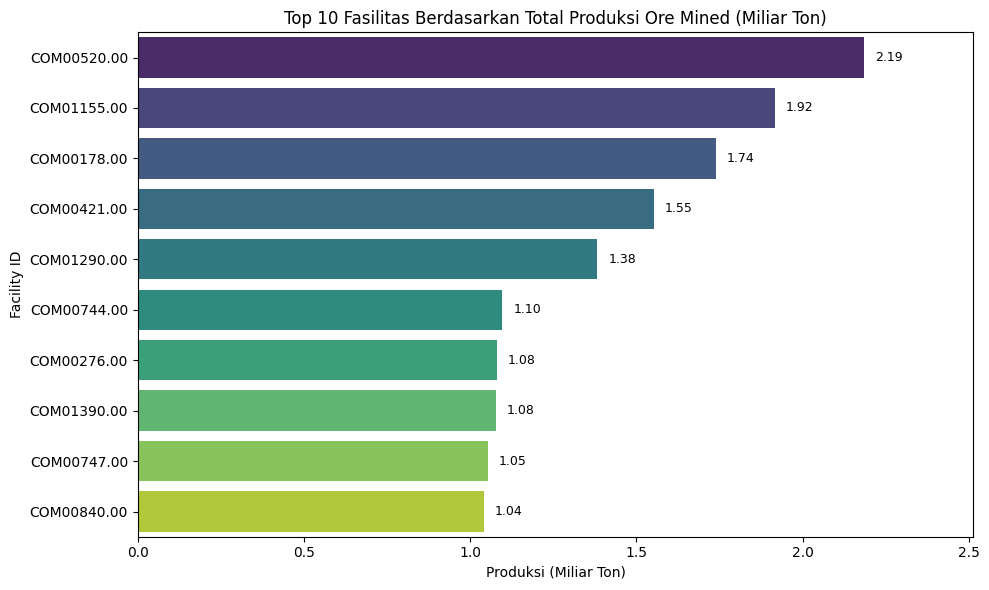

In [42]:
# Urutkan dari terbesar ke terkecil dan ambil 10 fasilitas teratas
top_10_fac = fac_count.sort_values(ascending=False).head(10)

# Konversi ke miliar ton (ubah ke / 1e6 jika angkanya lebih pas dalam juta ton)
x_vals = top_10_fac.values / 1e9
y_vals = top_10_fac.index.astype(str)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=x_vals, y=y_vals, hue=y_vals, palette="viridis", legend=False, ax=ax)

ax.set_title("Top 10 Fasilitas Berdasarkan Total Produksi Ore Mined (Miliar Ton)")
ax.set_xlabel("Produksi (Miliar Ton)")
ax.set_ylabel("Facility ID")

# Beri ruang ekstra di kanan agar label angka tidak terpotong
ax.set_xlim(0, x_vals.max() * 1.15)

for bar in ax.patches:
    val = bar.get_width()
    ax.text(
        val + (x_vals.max() * 0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{val:.2f}",
        va="center",
        ha="left",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

**Interpretation:**

Grafik *"Top 10 Fasilitas Berdasarkan Total Produksi Ore Mined (Miliar Ton)"* memperlihatkan bahwa kontribusi produksi di jajaran 10 besar fasilitas tergolong merata dan bertahap, tanpa ada satu fasilitas yang mendominasi secara ekstrem seperti pada grafik material sebelumnya.

* **Peringkat teratas (`COM00520.00`):**
  - Fasilitas ini mencatatkan total produksi tertinggi sebesar **2,19 miliar ton**, diikuti oleh `COM01155.00` di posisi kedua dengan **1,92 miliar ton**.


* **Kelompok menengah (`COM00178.00` – `COM01290.00`):**
  - Produksi bergerak turun bertahap dari **1,74 miliar ton** (`COM00178.00`), **1,55 miliar ton** (`COM00421.00`), hingga **1,38 miliar ton** (`COM01290.00`).


* **Kelompok bawah 10 besar (`COM00744.00` – `COM00840.00`):**
  - Lima fasilitas terbawah di daftar ini berada di kisaran yang sangat berdekatan, mulai dari **1,10 miliar ton** (`COM00744.00`), **1,08 miliar ton** (`COM00276.00` dan `COM01390.00`), **1,05 miliar ton** (`COM00747.00`), sampai **1,04 miliar ton** (`COM00840.00`).


* **Catatan format ID fasilitas:**
  - Kode ID di sumbu Y masih tampil dengan akhiran `.00` (seperti `COM00520.00`), yang biasanya muncul jika ID sempat terbaca sebagai tipe numerik/float sebelum diubah ke teks.



Singkatnya, total produksi *ore mined* di 10 fasilitas teratas terdistribusi cukup seimbang antara **1,04 miliar ton** dan **2,19 miliar ton**, dengan `COM00520.00` sebagai penyumbang terbesar.

Jumlah fasilitas unik (Ore mined): 524


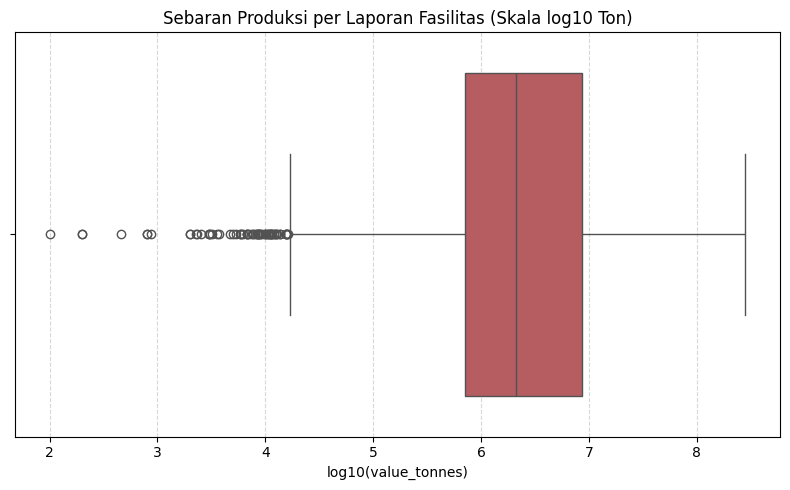

In [44]:
# Hitung jumlah fasilitas unik pada data Ore mined
jml_fasilitas = ore_mined["facility_id"].nunique()
print(f"Jumlah fasilitas unik (Ore mined): {jml_fasilitas}")

# Bersihkan nilai kosong/nol sebelum transformasi log10 agar tidak menghasilkan -inf/NaN
tonase_valid = ore_mined["value_tonnes"].dropna()
tonase_valid = tonase_valid[tonase_valid > 0]
log_tonase = np.log10(tonase_valid)

# Buat visualisasi boxplot dalam skala log10
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(x=log_tonase, color="#C44E52", ax=ax)

ax.set_title("Sebaran Produksi per Laporan Fasilitas (Skala log10 Ton)")
ax.set_xlabel("log10(value_tonnes)")
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Ada **524 fasilitas unik** yang tercatat pada kategori `Ore mined`, dan *boxplot* *"Sebaran Produksi per Laporan Fasilitas (Skala log10 Ton)"* memperlihatkan bahwa sebagian besar catatan produksi berada pada skala jutaan ton dengan sejumlah *outlier* bernilai jauh lebih kecil di sisi kiri.

* **Cakupan fasilitas luas (524 fasilitas):**
  - Terdapat 524 fasilitas unik yang berkontribusi pada data *ore mined*, menandakan sebaran operasi tambang yang cukup luas di dalam *dataset*.

* **Mayoritas produksi di skala jutaan ton:**
  - Kotak tengah (*interquartile range* / 50% data tengah) berada di sekitar `5,9` hingga `6,9` pada skala $\log_{10}$, dengan garis median di kisaran `6,35`. Dalam tonase asli, rentang ini setara dengan sekitar **0,8 juta hingga 8 juta ton** per catatan laporan (median sekitar **2,2 juta ton**).


* **Banyak *outlier* di sisi bawah (volume kecil):**
  - Titik-titik *outlier* mengumpul di bawah batas kumis kiri (sekitar `4,2` ke bawah hingga sekitar `2,0`, atau setara puluhan ribu hingga ratusan ton). Ini menunjukkan ada cukup banyak catatan laporan berskala kecil dibanding mayoritas data.


* **Tidak ada *outlier* ekstrem di sisi atas:**
  - Kumis kanan memanjang hingga sekitar `8,5` (sekitar **300-an juta ton**) tanpa titik *outlier* terpisah di atasnya.



Singkatnya, dari 524 fasilitas unik `Ore mined`, volume per laporan umumnya berada di kisaran jutaan ton dengan ekor *outlier* bervolume kecil di sisi kiri.

## Conclusions & Insights

Berikut adalah beberapa kesimpulan utama dan wawasan menarik yang dapat ditarik dari analisis data produksi tambang global (**Ore mined**):

### 1. Tren Produksi Global (2000–2020)
* **Pertumbuhan Signifikan (2000–2018):** Produksi bijih dunia meningkat pesat dari sekitar **1,40 miliar ton** pada tahun 2000 hingga mencapai puncaknya di angka **4,13 miliar ton** pada tahun 2018. Hal ini menunjukkan peningkatan kapasitas penambangan global yang masif dalam rentang waktu hampir dua dekade.
* **Kontraksi Tajam di Akhir Dekade:** Terjadi penurunan volume produksi yang sangat drastis pada tahun 2019 (**2,51 miliar ton**) dan 2020 (**0,43 billion ton**). Penurunan ekstrem ini kemungkinan disebabkan oleh faktor pembatasan akibat pandemi global atau keterlambatan serta ketidaklengkapan pelaporan data terbaru saat basis data ini disusun.

### 2. Dominasi Komoditas Tambang
* **Pilar Utama (Besi dan Tembaga):** Sebagian besar volume penambangan global didominasi oleh bijih besi (**O.Fe**) sebesar **17,93 miliar ton** dan tembaga (**O.Cu**) sebesar **10,61 miliar ton**.
* **Kesenjangan Skala:** Emas (**O.Au**) dan komoditas curah (**O.bulk**) menyusul sebagai kelompok besar berikutnya, sedangkan 6 dari 10 material teratas lainnya memiliki volume yang jauh lebih kecil di bawah angka miliaran ton.

### 3. Profil Fasilitas Tambang
* **Penyebaran Operasional:** Terdapat **524 fasilitas unik** yang tercatat melakukan aktivitas produksi *Ore mined*. Hal ini menunjukkan jangkauan industri pertambangan yang sangat luas dalam cakupan dataset ini.
* **Karakteristik Skala Produksi:** Mayoritas laporan operasional tahunan berada pada skala jutaan ton (dengan nilai tengah/median sekitar **2,2 juta ton** per laporan), dengan ekor sebaran (*outlier*) yang memanjang ke arah volume kecil (puluhan ribu ton).
* **Kontributor Teratas:** Produksi dari 10 fasilitas terbesar di dunia berkisar secara bertahap antara **1,04 miliar ton** hingga **2,19 miliar ton**, di mana fasilitas dengan ID `COM00520.00` menempati posisi puncak sebagai produsen bijih terbesar.